# AI651 Assignment 3 — Q6: experimental analysis and interpretation
**Student:** Huzaifa | **Roll No:** 25280009 | AI651 Deep Learning for Space, Time and Graphs, Fall 2026, Assignment 3

Everything here is computed from files written by `Q3_data_and_graph.ipynb` and `Q4_Q5_training.ipynb` (`results/*.json`, `checkpoints/*.npy`, `data/processed/*`). Nothing is typed in by hand and nothing is tuned on the test period.

In [1]:
import os, sys, json, glob
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from common import set_seed, save_json, load_json, PROC, RES, FIG, CKPT, SEED
set_seed(SEED); print('Global seed =', SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
R6 = {}
MODELS = [('temporal_only', 'Temporal-only', 'None'), ('stgnn_fixed', 'STGNN', 'Fixed'), ('stgnn_adaptive', 'STGNN', 'Adaptive'), ('stgnn_hybrid', 'STGNN', 'Hybrid')]
MODELS_EXT = [('temporal_only', 'Temporal-only', 'None'), ('stgnn_fixed_skip', 'STGNN + self path', 'Fixed'), ('stgnn_adaptive_skip', 'STGNN + self path', 'Adaptive'), ('stgnn_hybrid_skip', 'STGNN + self path', 'Hybrid')]
ALL = {n: (m, a) for n, m, a in MODELS + MODELS_EXT}
RES42 = {n: load_json(f'{RES}/train_{n}_seed42.json') for n in ALL}
HW = load_json(f'{RES}/hardware.json'); print('training device:', RES42['temporal_only']['device'], '|', HW.get('gpu') or HW['cpu_model'])

/home/huzaifa/miniconda3/envs/pa1/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Global seed = 42
training device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


## Q6(a) — Forecasting comparison (seed 42; test period Apr–Dec 2021; original units, vehicles per 15 min)

In [2]:
def fmt_time(s): return f'{s:.0f} s ({s/60:.1f} min)'
rows = [dict(Model=m, Adjacency=a, MAE=RES42[n]['test']['mae'], RMSE=RES42[n]['test']['rmse'], **{'Training time': fmt_time(RES42[n]['train_time_sec'])},
             Epochs=RES42[n]['epochs_run'], Best_epoch=RES42[n]['best_epoch'], Val_MAE=RES42[n]['val']['mae'], Val_RMSE=RES42[n]['val']['rmse'], Params=RES42[n]['params']) for n, m, a in MODELS]
T6a = pd.DataFrame(rows); print('TEST-period results (primary table):'); print(T6a.round(2).to_string(index=False))
ph = []
for n, m, a in MODELS:
    for sp in ('test', 'val'):
        r = RES42[n][sp]; ph.append(dict(split=sp, Model=m, Adjacency=a, **{f'MAE {15*(h+1)}min': r['mae_h'][h] for h in range(4)}, **{f'RMSE {15*(h+1)}min': r['rmse_h'][h] for h in range(4)}))
T6a_h = pd.DataFrame(ph); print('\nPer-horizon:'); print(T6a_h.round(2).to_string(index=False))
T6a.to_csv(f'{RES}/q6a_table_seed42.csv', index=False); T6a_h.to_csv(f'{RES}/q6a_per_horizon_seed42.csv', index=False)
# extension (self path) tables
T6e = pd.DataFrame([dict(Model=m, Adjacency=a, MAE=RES42[n]['test']['mae'], RMSE=RES42[n]['test']['rmse'], **{'Training time': fmt_time(RES42[n]['train_time_sec'])}, Epochs=RES42[n]['epochs_run'], Val_MAE=RES42[n]['val']['mae'], Params=RES42[n]['params'],
                         Alpha=RES42[n].get('alpha', float('nan'))) for n, m, a in MODELS_EXT])
print('\nEXTENSION (self path) TEST results:'); print(T6e.round(2).to_string(index=False))
T6e_h = pd.DataFrame([dict(split=sp, Model=m, Adjacency=a, **{f'MAE {15*(h+1)}min': RES42[n][sp]['mae_h'][h] for h in range(4)}, **{f'RMSE {15*(h+1)}min': RES42[n][sp]['rmse_h'][h] for h in range(4)}) for n, m, a in MODELS_EXT for sp in ('test', 'val')])
T6e.to_csv(f'{RES}/q6a_extension_table_seed42.csv', index=False); T6e_h.to_csv(f'{RES}/q6a_extension_per_horizon_seed42.csv', index=False)
HL = load_json(f'{RES}/q4_q5_summary.json')['historical_last']; R6['historical_last_test'] = dict(mae=HL['test']['mae'], rmse=HL['test']['rmse'], mae_h=HL['test']['mae_h'])
R6['alpha'] = {n: RES42[n].get('alpha') for n in ('stgnn_hybrid', 'stgnn_hybrid_skip')}

# relative differences vs temporal-only (test MAE)
base = RES42['temporal_only']['test']['mae']
R6['relative_to_temporal_test_mae_pct'] = {n: 100 * (RES42[n]['test']['mae'] - base) / base for n in ALL}
print('\nTest MAE change relative to temporal-only (%):', {k: round(v, 2) for k, v in R6['relative_to_temporal_test_mae_pct'].items()})

# extra seeds (if the optional multi-seed notebook was run)
seed_files = sorted(glob.glob(f'{RES}/train_*_seed*.json')); seeds = sorted({int(f.split('seed')[-1][:-5]) for f in seed_files})
agg = []
for n, (m, a) in ALL.items():
    vals = [load_json(f'{RES}/train_{n}_seed{s}.json') for s in seeds if os.path.exists(f'{RES}/train_{n}_seed{s}.json')]
    agg.append(dict(name=n, Model=m, Adjacency=a, n_seeds=len(vals), seeds=[v['seed'] for v in vals],
                    test_MAE_mean=np.mean([v['test']['mae'] for v in vals]), test_MAE_std=np.std([v['test']['mae'] for v in vals], ddof=1) if len(vals) > 1 else float('nan'),
                    test_RMSE_mean=np.mean([v['test']['rmse'] for v in vals]), test_RMSE_std=np.std([v['test']['rmse'] for v in vals], ddof=1) if len(vals) > 1 else float('nan'),
                    time_mean=np.mean([v['train_time_sec'] for v in vals]), time_std=np.std([v['train_time_sec'] for v in vals], ddof=1) if len(vals) > 1 else float('nan'),
                    per_seed_test_MAE=[v['test']['mae'] for v in vals]))
T6a_seeds = pd.DataFrame(agg); print('\nMulti-seed summary (mean +- sample std over the available seeds):'); print(T6a_seeds.drop(columns=['per_seed_test_MAE']).round(3).to_string(index=False))
T6a_seeds.to_csv(f'{RES}/q6a_multiseed.csv', index=False)

TEST-period results (primary table):
        Model Adjacency   MAE   RMSE    Training time  Epochs  Best_epoch  Val_MAE  Val_RMSE  Params
Temporal-only      None 61.76  96.95  234 s (3.9 min)      23          17    52.90     85.12   13828
        STGNN     Fixed 92.03 143.87  477 s (8.0 min)      45          39    78.26    129.68   14884
        STGNN  Adaptive 75.49 122.23 636 s (10.6 min)      52          46    59.30    104.69   29204
        STGNN    Hybrid 72.20 115.96 646 s (10.8 min)      52          46    57.31     98.71   29205

Per-horizon:
split         Model Adjacency  MAE 15min  MAE 30min  MAE 45min  MAE 60min  RMSE 15min  RMSE 30min  RMSE 45min  RMSE 60min
 test Temporal-only      None      43.79      56.49      67.75      79.04       67.55       87.70      104.35      120.23
  val Temporal-only      None      38.94      48.81      57.44      66.42       61.15       77.52       91.10      104.58
 test         STGNN     Fixed      84.20      89.37      94.38     100.18     


Multi-seed summary (mean +- sample std over the available seeds):
               name             Model Adjacency  n_seeds        seeds  test_MAE_mean  test_MAE_std  test_RMSE_mean  test_RMSE_std  time_mean  time_std
      temporal_only     Temporal-only      None        3 [42, 43, 44]         61.480         0.527          96.490          0.738    359.391   140.427
        stgnn_fixed             STGNN     Fixed        3 [42, 43, 44]         91.114         0.809         143.321          0.478    587.949    95.986
     stgnn_adaptive             STGNN  Adaptive        3 [42, 43, 44]         74.825         0.607         121.307          0.798    702.026    57.555
       stgnn_hybrid             STGNN    Hybrid        3 [42, 43, 44]         72.074         0.185         116.117          0.920    654.152    97.304
   stgnn_fixed_skip STGNN + self path     Fixed        3 [42, 43, 44]         56.496         0.183          88.708          0.143    459.040   100.371
stgnn_adaptive_skip STGNN +

### Predicted vs actual flow (test period), 3 sensors, 15-min and 60-min horizons
For a window anchored at time $t$ the horizon-$h$ prediction is for time $t+h$; the plotted curve is the horizon-$h$ prediction placed at its target time, so the 15-min row shows all one-step-ahead forecasts and the 60-min row all four-step-ahead forecasts. Sensors: 10th/50th/90th percentile of mean flow among sensors fully observed in the plotted window. Actual = observed values (gaps are real missing data).

plotted window 2021-06-07 00:00:00 -> 2021-06-10 23:45:00 | sensors [np.str_('1113486'), np.str_('1118537'), np.str_('1116119')]


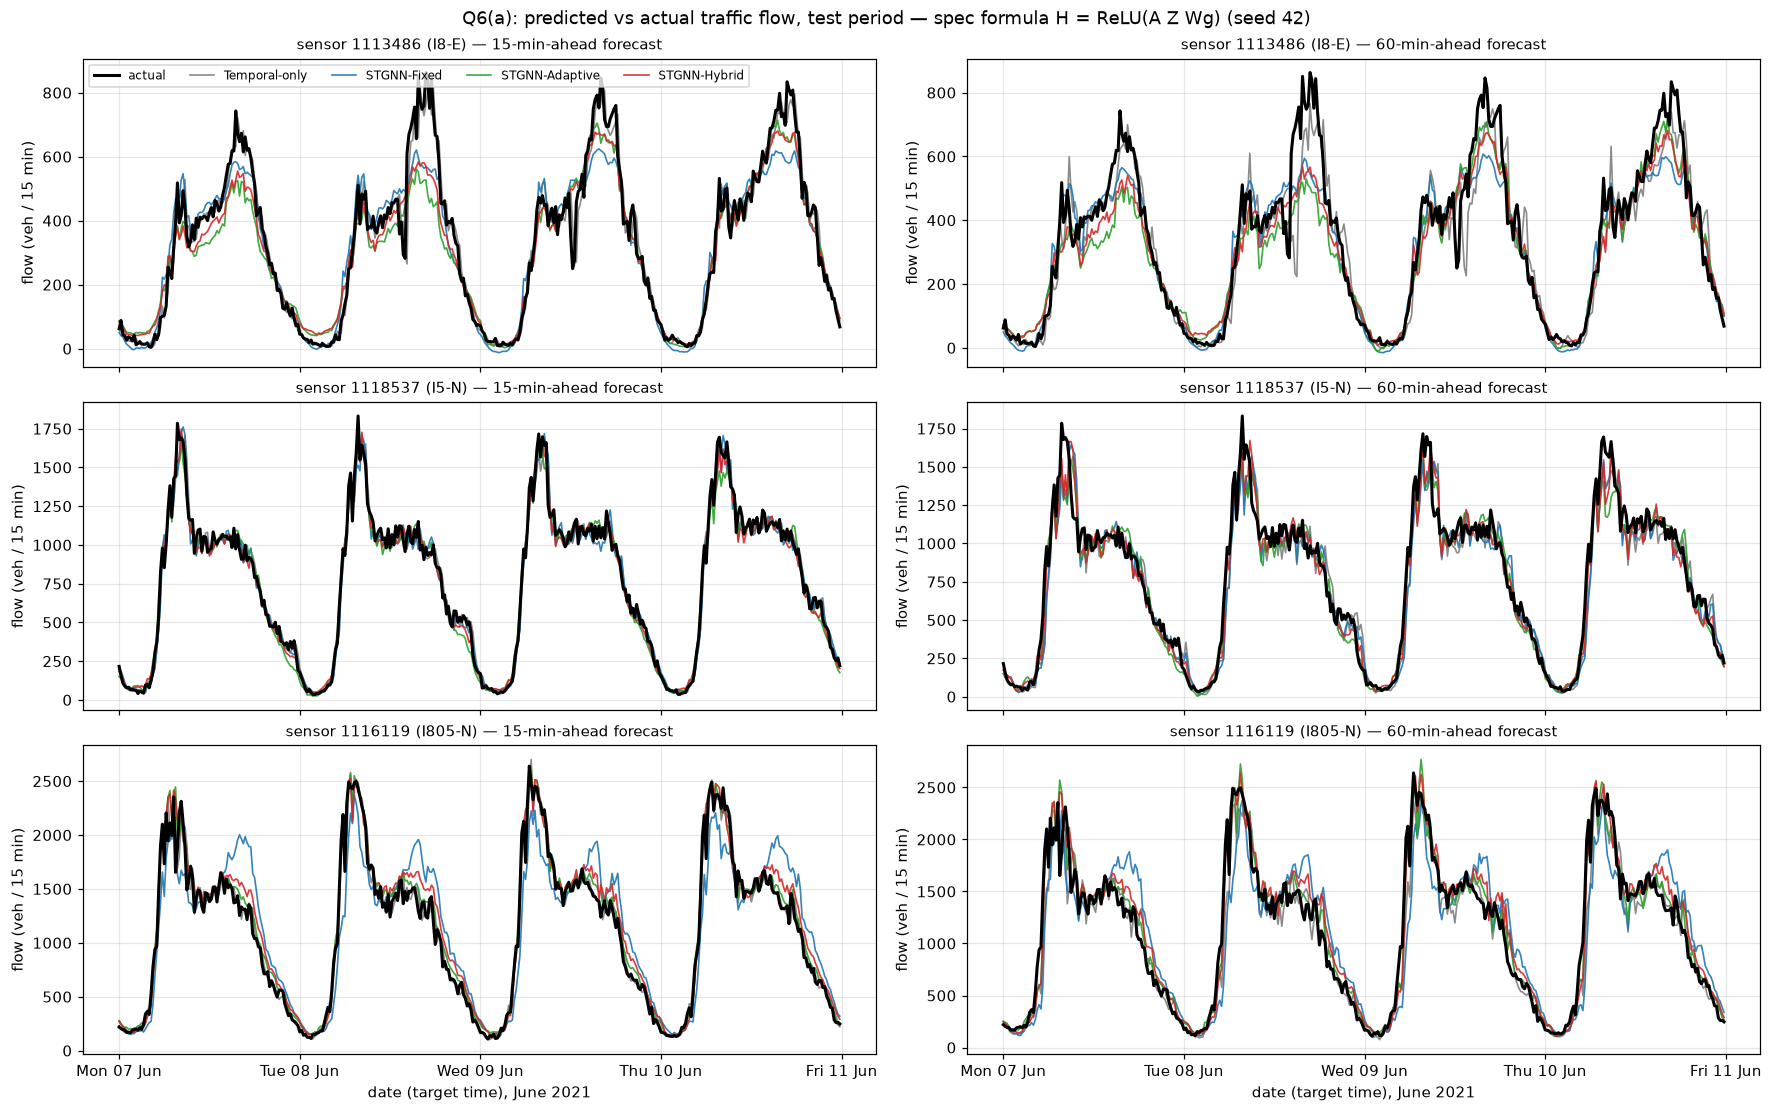

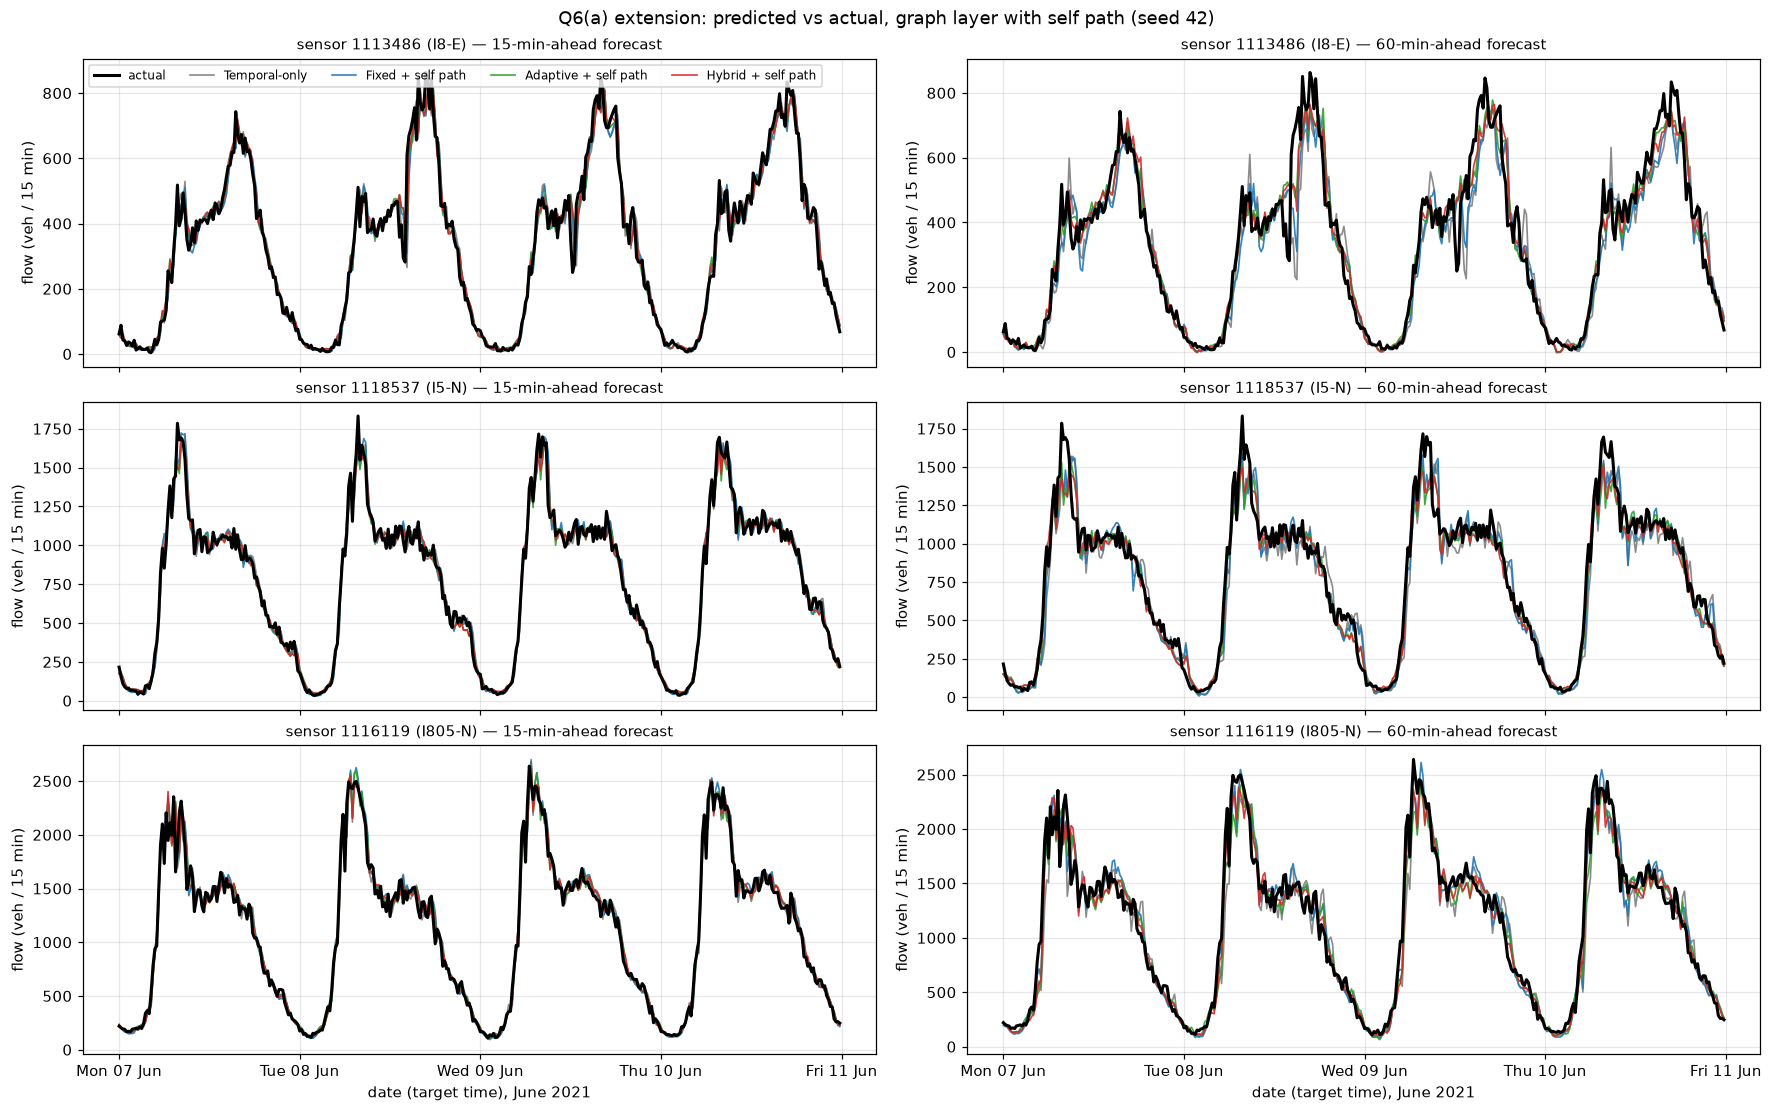

In [3]:
d = load_processed = None
times = pd.DatetimeIndex(np.load(f'{PROC}/sd_timestamps.npy')); Xraw = np.load(f'{PROC}/sd_flow_15min_raw.npy')[..., 0]; valid = np.load(f'{PROC}/sd_valid_mask.npy')
meta = pd.read_csv(f'{PROC}/sd_meta.csv'); ids = np.load(f'{PROC}/sd_sensor_ids.npy')
test0 = int(np.searchsorted(times, pd.Timestamp('2021-04-01'))); T_IN, T_OUT = 8, 4
PRED = {n: np.load(f'{CKPT}/pred_test_{n}_seed42.npy', mmap_mode='r') for n in ALL}      # (n_windows, 4, N) de-normalised
def pred_series(n, h, j, a, b):            # horizon index h (0..3), sensor j, target-time range [a, b)
    wi = np.arange(a, b) - (h + 1) - (test0 + T_IN - 1)                      # window whose anchor + (h+1) == target time
    assert wi.min() >= 0 and wi.max() < PRED[n].shape[0]; return np.asarray(PRED[n][wi, h, j])
ws, we = int(np.searchsorted(times, pd.Timestamp('2021-06-07'))), int(np.searchsorted(times, pd.Timestamp('2021-06-11')))      # Mon-Thu, 4 days
cand = np.where(valid[ws:we].all(0))[0]; order = np.argsort(Xraw[ws:we][:, cand].mean(0)); pick = [int(cand[order[int(q * (len(cand) - 1))]]) for q in (.1, .5, .9)]
print('plotted window', times[ws], '->', times[we - 1], '| sensors', [ids[p] for p in pick])
COL = {'temporal_only': 'tab:gray', 'stgnn_fixed': 'tab:blue', 'stgnn_adaptive': 'tab:green', 'stgnn_hybrid': 'tab:red', 'stgnn_fixed_skip': 'tab:blue', 'stgnn_adaptive_skip': 'tab:green', 'stgnn_hybrid_skip': 'tab:red'}
LAB = {'temporal_only': 'Temporal-only', 'stgnn_fixed': 'STGNN-Fixed', 'stgnn_adaptive': 'STGNN-Adaptive', 'stgnn_hybrid': 'STGNN-Hybrid', 'stgnn_fixed_skip': 'Fixed + self path', 'stgnn_adaptive_skip': 'Adaptive + self path', 'stgnn_hybrid_skip': 'Hybrid + self path'}
def pred_plot(models, fname, title):
    fig, axs = plt.subplots(3, 2, figsize=(16, 10), sharex=True, constrained_layout=True)
    for r_, j in enumerate(pick):
        for c_, h in enumerate((0, 3)):
            ax = axs[r_, c_]; ax.plot(times[ws:we], Xraw[ws:we, j], 'k', lw=2, label='actual', zorder=5)
            for n, _, _ in models: ax.plot(times[ws:we], pred_series(n, h, j, ws, we), color=COL[n], lw=1.1, label=LAB[n], alpha=.9)
            ax.set_ylabel('flow (veh / 15 min)'); ax.set_title(f'sensor {ids[j]} ({meta.Fwy[j]}) — {15*(h+1)}-min-ahead forecast', fontsize=10)
            if r_ == 0 and c_ == 0: ax.legend(ncol=5, fontsize=8, loc='upper left')
    for c_ in range(2):
        axs[-1, c_].xaxis.set_major_locator(mdates.DayLocator()); axs[-1, c_].xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b')); axs[-1, c_].set_xlabel('date (target time), June 2021')
    fig.suptitle(title); fig.savefig(f'{FIG}/{fname}', dpi=160); plt.show()
pred_plot(MODELS, 'q6a_pred_vs_actual.png', 'Q6(a): predicted vs actual traffic flow, test period — spec formula H = ReLU(A Z Wg) (seed 42)')
pred_plot(MODELS_EXT, 'q6a_pred_vs_actual_selfpath.png', 'Q6(a) extension: predicted vs actual, graph layer with self path (seed 42)')
R6['pred_plot'] = dict(window=[str(times[ws]), str(times[we - 1])], sensors=[str(ids[p]) for p in pick])

### Where do the models differ? Test MAE by hour of day and by sensor group

recomputed overall test MAE matches the stored metric for all four models


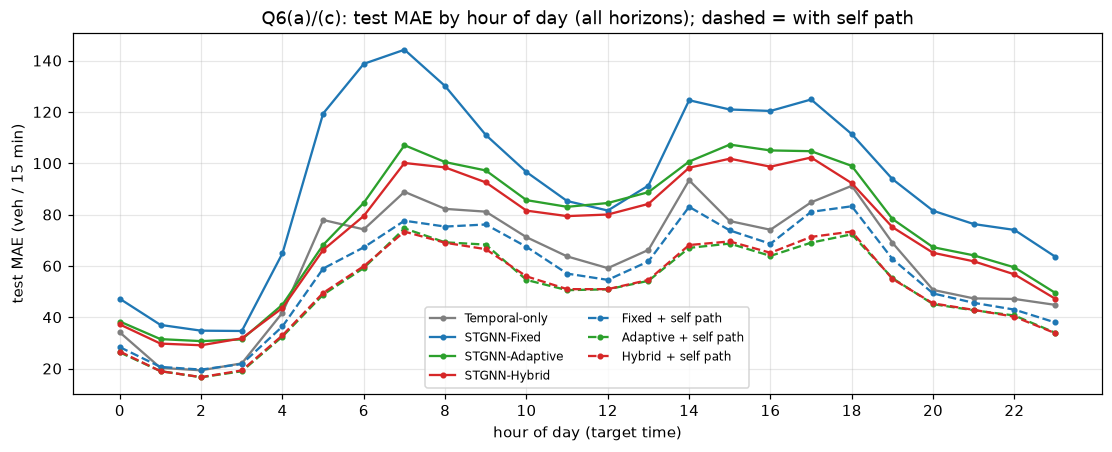

                     weekday  weekend  rush (7-9h, 16-18h)  night (0-5h)
temporal_only          65.68    51.90                82.48         27.49
stgnn_fixed            98.37    76.02               129.87         43.71
stgnn_adaptive         77.26    71.02               104.29         35.35
stgnn_hybrid           73.86    68.01                99.84         34.28
stgnn_fixed_skip       59.28    48.81                75.64         25.35
stgnn_adaptive_skip    52.58    43.84                69.18         22.66
stgnn_hybrid_skip      52.79    44.43                69.69         22.89


mean observed flow per period: {'train (2020)': 607.8, 'val (Jan-Mar 2021)': 635.8, 'test (Apr-Dec 2021)': 721.3}


fraction of sensors where the model has lower test MAE than temporal-only: {'stgnn_fixed': 0.0638930163447251, 'stgnn_adaptive': 0.45022288261515603, 'stgnn_hybrid': 0.5007429420505201, 'stgnn_fixed_skip': 0.9598811292719168, 'stgnn_adaptive_skip': 0.9881129271916791, 'stgnn_hybrid_skip': 0.9925705794947994}


In [4]:
Y_obs = np.stack([Xraw[test0 + T_IN + h: test0 + T_IN + h + PRED['temporal_only'].shape[0]] for h in range(4)], 1)      # (n_win, 4, N) observed targets (NaN = missing)
M_obs = ~np.isnan(Y_obs)
tgt_hour = np.stack([times[test0 + T_IN + h: test0 + T_IN + h + PRED['temporal_only'].shape[0]].hour.values for h in range(4)], 1)   # (n_win, 4)
hour_mae = {}
for n in ALL:
    P = np.asarray(PRED[n]); err = np.abs(P - np.nan_to_num(Y_obs)) * M_obs
    hour_mae[n] = [float(err[tgt_hour == hh].sum() / M_obs[tgt_hour == hh].sum()) for hh in range(24)]
    # sanity: identical to metric stored by the training code
    assert abs(err.sum() / M_obs.sum() - RES42[n]['test']['mae']) < 1e-2, (n, err.sum() / M_obs.sum(), RES42[n]['test']['mae'])
print('recomputed overall test MAE matches the stored metric for all four models')
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for n in ALL: ax.plot(range(24), hour_mae[n], marker='o', ms=3, color=COL[n], ls='--' if n.endswith('skip') else '-', label=LAB[n])
ax.set_xlabel('hour of day (target time)'); ax.set_ylabel('test MAE (veh / 15 min)'); ax.set_title('Q6(a)/(c): test MAE by hour of day (all horizons); dashed = with self path'); ax.legend(ncol=2, fontsize=8); ax.set_xticks(range(0, 24, 2))
fig.savefig(f'{FIG}/q6a_mae_by_hour.png', dpi=160); plt.show()
R6['hour_mae'] = hour_mae
# weekday / weekend and rush-hour / night error (time-varying structure that a static graph cannot represent)
tgt_dow = np.stack([times[test0 + T_IN + h: test0 + T_IN + h + PRED['temporal_only'].shape[0]].dayofweek.values for h in range(4)], 1)
def grp_mae(n, sel):
    P = np.asarray(PRED[n]); e = np.abs(P - np.nan_to_num(Y_obs)) * M_obs; return float(e[sel[..., None] & np.ones_like(M_obs, bool)].sum() / M_obs[sel[..., None] & np.ones_like(M_obs, bool)].sum())
masks = {'weekday': tgt_dow < 5, 'weekend': tgt_dow >= 5, 'rush (7-9h, 16-18h)': np.isin(tgt_hour, [7, 8, 16, 17]), 'night (0-5h)': tgt_hour < 5}
R6['group_mae'] = {n: {g: grp_mae(n, m) for g, m in masks.items()} for n in ALL}
print(pd.DataFrame(R6['group_mae']).T.round(2).to_string())
R6['flow_by_group'] = {g: float(np.nansum(np.where(m[..., None], Y_obs, 0)) / (M_obs & m[..., None]).sum()) for g, m in masks.items()}
# distribution shift between the three periods (observed mean flow, original units)
sl_ = {'train (2020)': (0, int(np.searchsorted(times, pd.Timestamp('2021-01-01')))), 'val (Jan-Mar 2021)': (int(np.searchsorted(times, pd.Timestamp('2021-01-01'))), test0), 'test (Apr-Dec 2021)': (test0, len(times))}
R6['split_mean_flow'] = {k: float(np.nanmean(np.where(valid[a:b], Xraw[a:b], np.nan))) for k, (a, b) in sl_.items()}
print('mean observed flow per period:', {k: round(v, 1) for k, v in R6['split_mean_flow'].items()})
# per-sensor MAE (flow-level groups)
sens_mae = {n: (np.abs(np.asarray(PRED[n]) - np.nan_to_num(Y_obs)) * M_obs).sum((0, 1)) / np.maximum(M_obs.sum((0, 1)), 1) for n in ALL}
ok = M_obs.sum((0, 1)) > 1000
R6['per_sensor'] = {n: dict(mean=float(v[ok].mean()), median=float(np.median(v[ok])), p90=float(np.quantile(v[ok], .9))) for n, v in sens_mae.items()}
R6['frac_sensors_better_than_temporal'] = {n: float(np.mean(sens_mae[n][ok] < sens_mae['temporal_only'][ok])) for n in ALL if n != 'temporal_only'}
print('fraction of sensors where the model has lower test MAE than temporal-only:', R6['frac_sensors_better_than_temporal'])

In [5]:
from IPython.display import Markdown, display
NARR = {}
def narrate(key, text):
    NARR[key] = text; display(Markdown(text))
SD = {r['name']: r for r in agg}                                               # multi-seed aggregates
mae = lambda n: RES42[n]['test']['mae']; rmse = lambda n: RES42[n]['test']['rmse']
pm = lambda n, k='MAE': (f"{SD[n]['test_MAE_mean']:.1f} ± {SD[n]['test_MAE_std']:.1f}" if k == 'MAE' else f"{SD[n]['test_RMSE_mean']:.1f} ± {SD[n]['test_RMSE_std']:.1f}")
nseeds = SD['temporal_only']['n_seeds']; seeds_txt = ', '.join(str(x) for x in SD['temporal_only']['seeds'])
rel = R6['relative_to_temporal_test_mae_pct']
mh = lambda n: RES42[n]['test']['mae_h']
better_h = lambda n: [15 * (h + 1) for h in range(4) if mh(n)[h] < mh('temporal_only')[h]]
tl = lambda n: RES42[n]['history'][-1]['train_loss_norm'] * load_json(f'{RES}/q4_q5_summary.json')['Q4a']['global_std']     # final training loss in raw units
sec_ep = lambda n: RES42[n]['train_time_sec'] / RES42[n]['epochs_run']
def _per_seed(n): return {s_: load_json(f'{RES}/train_{n}_seed{s_}.json')['test']['mae'] for s_ in (42, 43, 44) if os.path.exists(f'{RES}/train_{n}_seed{s_}.json')}
_ps = {n: _per_seed(n) for n in ALL}; _common = sorted(set.intersection(*[set(v) for v in _ps.values()]))
consistent_literal = all(_ps['temporal_only'][k] < min(_ps['stgnn_fixed'][k], _ps['stgnn_adaptive'][k], _ps['stgnn_hybrid'][k]) for k in _common)
consistent_skip = all(max(_ps['stgnn_fixed_skip'][k], _ps['stgnn_adaptive_skip'][k], _ps['stgnn_hybrid_skip'][k]) < _ps['temporal_only'][k] for k in _common)

### Q6(a) — discussion of the comparison (all numbers below are filled in from the saved result files)

In [6]:
_Af = np.load(f'{CKPT}/A_used_stgnn_fixed_seed42.npy'); _Aa = np.load(f'{CKPT}/A_adaptive_stgnn_adaptive_seed42.npy'); _Fo = _Af.copy(); np.fill_diagonal(_Fo, 0)
GX = dict(fixed_self=float(np.diag(_Af).mean()), fixed_self_median=float(np.median(np.diag(_Af))), eff_fixed=float(np.mean(1 / (_Af ** 2).sum(1))), eff_adp=float(np.mean(1 / (_Aa ** 2).sum(1))), adp_max=float(_Aa.max(1).mean()), fixed_max=float(_Fo.max(1).mean()))
txt = f"""**Main table (seed 42, test period, vehicles per 15 min).** Temporal-only: MAE {mae('temporal_only'):.2f} / RMSE {rmse('temporal_only'):.2f}; STGNN-Fixed {mae('stgnn_fixed'):.2f} / {rmse('stgnn_fixed'):.2f}; STGNN-Adaptive {mae('stgnn_adaptive'):.2f} / {rmse('stgnn_adaptive'):.2f}; STGNN-Hybrid {mae('stgnn_hybrid'):.2f} / {rmse('stgnn_hybrid'):.2f}. Over {nseeds} seeds ({seeds_txt}) the test MAE (mean ± sample std) is {pm('temporal_only')} (temporal-only), {pm('stgnn_fixed')} (fixed), {pm('stgnn_adaptive')} (adaptive), {pm('stgnn_hybrid')} (hybrid). {'In every seed the temporal-only model has a lower test MAE than each of the three graph models.' if consistent_literal else 'The ordering between temporal-only and the graph models is not identical in every seed (see the multi-seed table).'} For reference the non-learned "historical last" baseline has test MAE {R6['historical_last_test']['mae']:.2f}.

**Honest reading of the main table.** With the layer exactly as specified, H = ReLU(Â Z W_g), **none of the graph models beats the temporal-only model**: relative to temporal-only the test MAE is {rel['stgnn_fixed']:+.1f} % (fixed), {rel['stgnn_adaptive']:+.1f} % (adaptive) and {rel['stgnn_hybrid']:+.1f} % (hybrid); the fixed-graph model is even worse than historical-last ({R6['historical_last_test']['mae']:.1f}). The training errors show two different failure modes. *Fixed graph — under-fitting:* the final training MAE (raw units) is {tl('stgnn_fixed'):.1f} versus {tl('temporal_only'):.1f} for temporal-only. In H = ReLU(Â Z W_g) a sensor's output is built **only** from a weighted average of its neighbours' features; in the fixed row-normalised road graph the sensor keeps on average {100*GX['fixed_self']:.1f} % of the weight (median {100*GX['fixed_self_median']:.1f} %; ≈ {GX['eff_fixed']:.1f} effective neighbours per row), so the layer largely replaces the sensor's own recent history — the most informative input — by a blurred regional average, and the model cannot fit even the training data. *Adaptive and hybrid — they fit the training data as well as temporal-only but generalise worse:* training MAE {tl('stgnn_adaptive'):.1f} (adaptive) and {tl('stgnn_hybrid'):.1f} (hybrid) versus {tl('temporal_only'):.1f}, but validation MAE {RES42['stgnn_adaptive']['val']['mae']:.1f} / {RES42['stgnn_hybrid']['val']['mae']:.1f} versus {RES42['temporal_only']['val']['mae']:.1f} and test MAE {mae('stgnn_adaptive'):.1f} / {mae('stgnn_hybrid'):.1f} versus {mae('temporal_only'):.1f} (train→test gap {mae('stgnn_adaptive')-tl('stgnn_adaptive'):.1f} / {mae('stgnn_hybrid')-tl('stgnn_hybrid'):.1f} versus {mae('temporal_only')-tl('temporal_only'):.1f}). Their learned graphs are sharper than the road graph ({GX['eff_adp']:.1f} effective neighbours, mean largest weight {GX['adp_max']:.2f} versus {GX['fixed_max']:.2f}), so they can reproduce the training targets, but a representation built from other sensors' features transfers worse to later periods. The periods do differ: the mean observed flow is {R6['split_mean_flow']['train (2020)']:.0f} (train, 2020), {R6['split_mean_flow']['val (Jan-Mar 2021)']:.0f} (validation) and {R6['split_mean_flow']['test (Apr-Dec 2021)']:.0f} (test) vehicles per 15 min, i.e. the test period has a different traffic level than the training year (a likely, but here untested, contributor to the larger generalisation gap of the models that rely on neighbours).

**Per horizon.** Temporal-only is far better at the shortest horizon (15 min MAE {mh('temporal_only')[0]:.1f} vs {mh('stgnn_fixed')[0]:.1f} / {mh('stgnn_adaptive')[0]:.1f} / {mh('stgnn_hybrid')[0]:.1f} for fixed / adaptive / hybrid), where a sensor's own last readings dominate; its error then grows quickly with the horizon ({mh('temporal_only')[0]:.1f} → {mh('temporal_only')[3]:.1f} at 60 min), whereas the spec-formula graph models are almost flat ({mh('stgnn_hybrid')[0]:.1f} → {mh('stgnn_hybrid')[3]:.1f} for hybrid). Horizons (minutes) at which each graph model beats temporal-only on the test period: fixed {better_h('stgnn_fixed') or 'none'}, adaptive {better_h('stgnn_adaptive') or 'none'}, hybrid {better_h('stgnn_hybrid') or 'none'}.

**Extension: the same graphs with a self path** H = ReLU(Â Z W_g + Z W_s) (identical protocol; documented as an extension, *not* the assignment's formula). Test MAE / RMSE: fixed {mae('stgnn_fixed_skip'):.2f} / {rmse('stgnn_fixed_skip'):.2f}, adaptive {mae('stgnn_adaptive_skip'):.2f} / {rmse('stgnn_adaptive_skip'):.2f}, hybrid {mae('stgnn_hybrid_skip'):.2f} / {rmse('stgnn_hybrid_skip'):.2f}; over {nseeds} seeds {pm('stgnn_fixed_skip')}, {pm('stgnn_adaptive_skip')}, {pm('stgnn_hybrid_skip')}. Relative to temporal-only the test MAE changes by {rel['stgnn_fixed_skip']:+.1f} % (fixed), {rel['stgnn_adaptive_skip']:+.1f} % (adaptive), {rel['stgnn_hybrid_skip']:+.1f} % (hybrid){' and this holds in every seed' if consistent_skip else ' (not identical in every seed, see the multi-seed table)'}. **Once a sensor keeps its own signal, spatial modelling helps**, and the benefit grows with the horizon (60-min MAE {mh('temporal_only')[3]:.1f} → {mh('stgnn_fixed_skip')[3]:.1f} / {mh('stgnn_adaptive_skip')[3]:.1f} / {mh('stgnn_hybrid_skip')[3]:.1f}; at 15 min {mh('temporal_only')[0]:.1f} → {mh('stgnn_fixed_skip')[0]:.1f} / {mh('stgnn_adaptive_skip')[0]:.1f} / {mh('stgnn_hybrid_skip')[0]:.1f}), consistent with neighbours carrying information about upstream conditions that reaches the sensor later. The learned graph is better than the road graph here ({R6['frac_sensors_better_than_temporal']['stgnn_adaptive_skip']*100:.0f} % of sensors have a lower test MAE than temporal-only with the adaptive graph, {R6['frac_sensors_better_than_temporal']['stgnn_fixed_skip']*100:.0f} % with the fixed graph).

**Does explicit spatial modelling improve accuracy? (Q4(c))** It does if the graph layer *adds to* the sensor's own temporal features: the test MAE falls by {-rel['stgnn_adaptive_skip']:.1f} % (adaptive graph, self path) and {-rel['stgnn_fixed_skip']:.1f} % (road graph, self path) relative to the temporal-only model. With the layer exactly as specified (neighbour average only) spatial modelling makes the forecast worse.

**Training time.** Seed-42 wall-clock (train + per-epoch validation, GPU {HW.get('gpu')}): temporal-only {fmt_time(RES42['temporal_only']['train_time_sec'])} over {RES42['temporal_only']['epochs_run']} epochs ({sec_ep('temporal_only'):.1f} s/epoch), fixed {fmt_time(RES42['stgnn_fixed']['train_time_sec'])} ({RES42['stgnn_fixed']['epochs_run']} epochs, {sec_ep('stgnn_fixed'):.1f} s/epoch), adaptive {fmt_time(RES42['stgnn_adaptive']['train_time_sec'])} ({RES42['stgnn_adaptive']['epochs_run']} epochs, {sec_ep('stgnn_adaptive'):.1f} s/epoch), hybrid {fmt_time(RES42['stgnn_hybrid']['train_time_sec'])} ({RES42['stgnn_hybrid']['epochs_run']} epochs, {sec_ep('stgnn_hybrid'):.1f} s/epoch). The fixed graph layer adds only {sec_ep('stgnn_fixed')-sec_ep('temporal_only'):.1f} s/epoch; the learnable graphs add the top-k selection and {RES42['stgnn_adaptive']['params']-RES42['stgnn_fixed']['params']:,} embedding parameters (+{sec_ep('stgnn_adaptive')-sec_ep('stgnn_fixed'):.1f} s/epoch versus fixed) and, here, also needed more epochs before the validation MAE stopped improving ({RES42['stgnn_adaptive']['epochs_run']} vs {RES42['stgnn_fixed']['epochs_run']}): the adaptive model's total time is {RES42['stgnn_adaptive']['train_time_sec']/RES42['stgnn_fixed']['train_time_sec']:.2f}× the fixed model's ({sec_ep('stgnn_adaptive')/sec_ep('stgnn_fixed'):.2f}× per epoch, {RES42['stgnn_adaptive']['epochs_run']/RES42['stgnn_fixed']['epochs_run']:.2f}× epochs). Each time is a single measurement that includes early-stopping dynamics, so only large differences are meaningful."""
narrate('6a', txt)

**Main table (seed 42, test period, vehicles per 15 min).** Temporal-only: MAE 61.76 / RMSE 96.95; STGNN-Fixed 92.03 / 143.87; STGNN-Adaptive 75.49 / 122.23; STGNN-Hybrid 72.20 / 115.96. Over 3 seeds (42, 43, 44) the test MAE (mean ± sample std) is 61.5 ± 0.5 (temporal-only), 91.1 ± 0.8 (fixed), 74.8 ± 0.6 (adaptive), 72.1 ± 0.2 (hybrid). In every seed the temporal-only model has a lower test MAE than each of the three graph models. For reference the non-learned "historical last" baseline has test MAE 87.18.

**Honest reading of the main table.** With the layer exactly as specified, H = ReLU(Â Z W_g), **none of the graph models beats the temporal-only model**: relative to temporal-only the test MAE is +49.0 % (fixed), +22.2 % (adaptive) and +16.9 % (hybrid); the fixed-graph model is even worse than historical-last (87.2). The training errors show two different failure modes. *Fixed graph — under-fitting:* the final training MAE (raw units) is 74.4 versus 52.0 for temporal-only. In H = ReLU(Â Z W_g) a sensor's output is built **only** from a weighted average of its neighbours' features; in the fixed row-normalised road graph the sensor keeps on average 17.3 % of the weight (median 14.1 %; ≈ 13.7 effective neighbours per row), so the layer largely replaces the sensor's own recent history — the most informative input — by a blurred regional average, and the model cannot fit even the training data. *Adaptive and hybrid — they fit the training data as well as temporal-only but generalise worse:* training MAE 52.2 (adaptive) and 50.9 (hybrid) versus 52.0, but validation MAE 59.3 / 57.3 versus 52.9 and test MAE 75.5 / 72.2 versus 61.8 (train→test gap 23.3 / 21.3 versus 9.8). Their learned graphs are sharper than the road graph (7.6 effective neighbours, mean largest weight 0.30 versus 0.14), so they can reproduce the training targets, but a representation built from other sensors' features transfers worse to later periods. The periods do differ: the mean observed flow is 608 (train, 2020), 636 (validation) and 721 (test) vehicles per 15 min, i.e. the test period has a different traffic level than the training year (a likely, but here untested, contributor to the larger generalisation gap of the models that rely on neighbours).

**Per horizon.** Temporal-only is far better at the shortest horizon (15 min MAE 43.8 vs 84.2 / 69.5 / 66.0 for fixed / adaptive / hybrid), where a sensor's own last readings dominate; its error then grows quickly with the horizon (43.8 → 79.0 at 60 min), whereas the spec-formula graph models are almost flat (66.0 → 78.6 for hybrid). Horizons (minutes) at which each graph model beats temporal-only on the test period: fixed none, adaptive none, hybrid [60].

**Extension: the same graphs with a self path** H = ReLU(Â Z W_g + Z W_s) (identical protocol; documented as an extension, *not* the assignment's formula). Test MAE / RMSE: fixed 56.31 / 88.56, adaptive 50.10 / 79.65, hybrid 50.42 / 80.04; over 3 seeds 56.5 ± 0.2, 50.2 ± 0.1, 50.6 ± 0.2. Relative to temporal-only the test MAE changes by -8.8 % (fixed), -18.9 % (adaptive), -18.4 % (hybrid) and this holds in every seed. **Once a sensor keeps its own signal, spatial modelling helps**, and the benefit grows with the horizon (60-min MAE 79.0 → 70.2 / 60.4 / 61.0; at 15 min 43.8 → 41.6 / 39.1 / 39.1), consistent with neighbours carrying information about upstream conditions that reaches the sensor later. The learned graph is better than the road graph here (99 % of sensors have a lower test MAE than temporal-only with the adaptive graph, 96 % with the fixed graph).

**Does explicit spatial modelling improve accuracy? (Q4(c))** It does if the graph layer *adds to* the sensor's own temporal features: the test MAE falls by 18.9 % (adaptive graph, self path) and 8.8 % (road graph, self path) relative to the temporal-only model. With the layer exactly as specified (neighbour average only) spatial modelling makes the forecast worse.

**Training time.** Seed-42 wall-clock (train + per-epoch validation, GPU NVIDIA GeForce RTX 4060 Laptop GPU): temporal-only 234 s (3.9 min) over 23 epochs (10.2 s/epoch), fixed 477 s (8.0 min) (45 epochs, 10.6 s/epoch), adaptive 636 s (10.6 min) (52 epochs, 12.2 s/epoch), hybrid 646 s (10.8 min) (52 epochs, 12.4 s/epoch). The fixed graph layer adds only 0.4 s/epoch; the learnable graphs add the top-k selection and 14,320 embedding parameters (+1.6 s/epoch versus fixed) and, here, also needed more epochs before the validation MAE stopped improving (52 vs 45): the adaptive model's total time is 1.33× the fixed model's (1.15× per epoch, 1.16× epochs). Each time is a single measurement that includes early-stopping dynamics, so only large differences are meaningful.

## Q6(b) — Learned-graph analysis
Learned graph = $A_{adp}$ of the *adaptive* model (seed 42; the model that follows the assignment formula), 716 rows each with 20 non-zero softmax weights; for completeness the same statistics are computed for the adaptive part of the hybrid model and for the two models with a self path. Row $i$ lists the sensors whose features are aggregated into sensor $i$ (same convention as the road graph $A_{ij}\ne0\Leftrightarrow j\in\mathcal N(i)$). All statistics use only the learned matrix, sensor meta data (lat/lon) and the **2020 training year** for correlations — no validation or test data.

In [7]:
A_road = np.load(f'{PROC}/sd_adj.npy'); np.fill_diagonal(A_road, 0); road = A_road > 0; road_any = road | road.T
DIST = np.load(f'{PROC}/sd_dist_km.npy'); N = 716; eye = np.eye(N, dtype=bool)
LA = {'adaptive model': np.load(f'{CKPT}/A_adaptive_stgnn_adaptive_seed42.npy'), 'hybrid model (adaptive part)': np.load(f'{CKPT}/A_adaptive_stgnn_hybrid_seed42.npy'),
      'adaptive model + self path': np.load(f'{CKPT}/A_adaptive_stgnn_adaptive_skip_seed42.npy'), 'hybrid model + self path (adaptive part)': np.load(f'{CKPT}/A_adaptive_stgnn_hybrid_skip_seed42.npy')}
rng = np.random.default_rng(SEED); Q = {}
for nm, A in LA.items():
    q = {}
    off = A.copy(); np.fill_diagonal(off, 0)
    q['diag_mass_mean'] = float(np.diag(A).mean()); q['self_in_topk_frac'] = float((np.diag(A) > 0).mean())
    # (1) overlap@k : per row, take the k strongest learned NON-SELF edges; fraction that are road edges (directed i->j, and in either direction)
    for k in (1, 5, 10, 19):
        idx = np.argsort(-off, axis=1)[:, :k]; hit = road[np.arange(N)[:, None], idx]; hit_any = road_any[np.arange(N)[:, None], idx]
        q[f'overlap_at_{k}_directed'] = float(hit.mean()); q[f'overlap_at_{k}_either_dir'] = float(hit_any.mean())
    # all learned non-self edges
    L_edges = off > 0; q['n_learned_edges_nonself'] = int(L_edges.sum()); q['frac_learned_edges_in_road'] = float((L_edges & road).sum() / L_edges.sum()); q['frac_learned_edges_in_road_either'] = float((L_edges & road_any).sum() / L_edges.sum())
    q['road_edge_density'] = float(road.sum() / (N * (N - 1))); q['road_edge_density_either'] = float(road_any.sum() / (N * (N - 1)))
    q['frac_road_edges_recovered'] = float((L_edges & road).sum() / road.sum())
    # global top-K strongest learned edges
    flat = off.ravel(); order_ = np.argsort(-flat)
    for K_ in (500, 2000, 5000):
        sel = order_[:K_]; q[f'global_top{K_}_in_road'] = float(road.ravel()[sel].mean()); q[f'global_top{K_}_in_road_either'] = float(road_any.ravel()[sel].mean())
    q['mean_weight_road_edges'] = float(off[L_edges & road].mean()) if (L_edges & road).any() else float('nan'); q['mean_weight_nonroad_edges'] = float(off[L_edges & ~road_any].mean())
    # (2) geographic distance
    d_l = DIST[L_edges]; d_road = DIST[road]; d_rand = DIST[~eye][rng.choice(N * (N - 1), 200000, replace=False)]
    d_rand_all = DIST[~eye]
    top = order_[:2000]; d_top = DIST.ravel()[top]
    q['dist_km'] = {k: dict(median=float(np.median(v)), mean=float(v.mean()), p25=float(np.quantile(v, .25)), p75=float(np.quantile(v, .75)), p90=float(np.quantile(v, .9)), frac_lt_5km=float((v < 5).mean()), frac_lt_2km=float((v < 2).mean()))
                    for k, v in (('learned_all', d_l), ('learned_top2000', d_top), ('road_edges', d_road), ('random_pairs', d_rand_all))}
    Q[nm] = q
    print(f'--- {nm} ---'); print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in q.items() if k != 'dist_km'}, indent=0)); print(pd.DataFrame(q['dist_km']).T.round(2).to_string())
R6['learned_graph'] = Q

--- adaptive model ---
{
"diag_mass_mean": 0.0452,
"self_in_topk_frac": 0.095,
"overlap_at_1_directed": 0.25,
"overlap_at_1_either_dir": 0.3408,
"overlap_at_5_directed": 0.1176,
"overlap_at_5_either_dir": 0.1522,
"overlap_at_10_directed": 0.0797,
"overlap_at_10_either_dir": 0.1008,
"overlap_at_19_directed": 0.0603,
"overlap_at_19_either_dir": 0.0753,
"n_learned_edges_nonself": 14252,
"frac_learned_edges_in_road": 0.0585,
"frac_learned_edges_in_road_either": 0.0734,
"road_edge_density": 0.0338,
"road_edge_density_either": 0.0411,
"frac_road_edges_recovered": 0.0482,
"global_top500_in_road": 0.304,
"global_top500_in_road_either": 0.418,
"global_top2000_in_road": 0.1655,
"global_top2000_in_road_either": 0.2145,
"global_top5000_in_road": 0.0964,
"global_top5000_in_road_either": 0.1234,
"mean_weight_road_edges": 0.1113,
"mean_weight_nonroad_edges": 0.0424
}
                 median   mean   p25    p75    p90  frac_lt_5km  frac_lt_2km
learned_all       15.51  20.71  6.16  31.59  47.12        

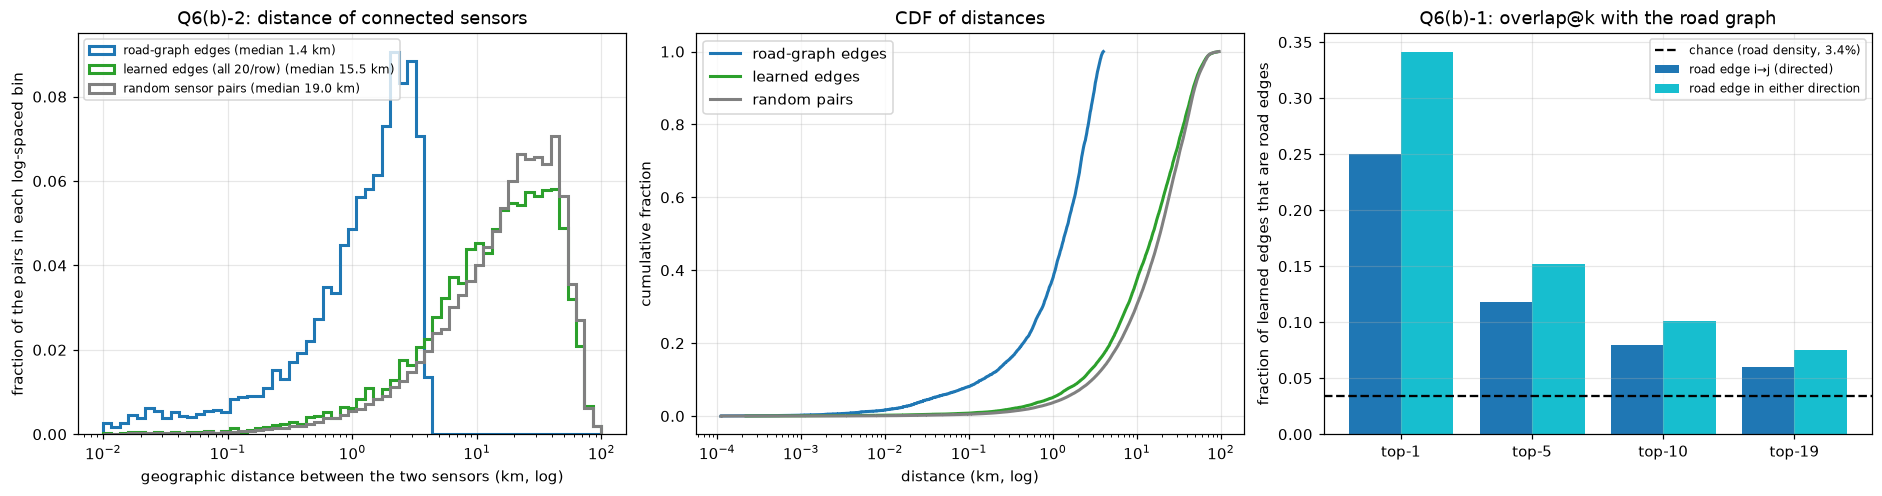

In [8]:
A = LA['adaptive model']; off = A.copy(); np.fill_diagonal(off, 0); L_edges = off > 0
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True)
bins = np.logspace(-2, 2.0, 60)
for lab, v, c in (('road-graph edges', DIST[road], 'tab:blue'), ('learned edges (all 20/row)', DIST[L_edges], 'tab:green'), ('random sensor pairs', DIST[~eye], 'gray')):
    ax[0].hist(v, bins=bins, weights=np.full(len(v), 1.0 / len(v)), histtype='step', lw=2, color=c, label=f'{lab} (median {np.median(v):.1f} km)')
ax[0].set_xscale('log'); ax[0].set_xlabel('geographic distance between the two sensors (km, log)'); ax[0].set_ylabel('fraction of the pairs in each log-spaced bin'); ax[0].set_title('Q6(b)-2: distance of connected sensors'); ax[0].legend(fontsize=8)
for lab, v, c in (('road-graph edges', DIST[road], 'tab:blue'), ('learned edges', DIST[L_edges], 'tab:green'), ('random pairs', DIST[~eye], 'gray')):
    s_ = np.sort(v); ax[1].plot(s_, np.arange(1, len(s_) + 1) / len(s_), color=c, lw=2, label=lab)
ax[1].set_xscale('log'); ax[1].set_xlabel('distance (km, log)'); ax[1].set_ylabel('cumulative fraction'); ax[1].set_title('CDF of distances'); ax[1].legend()
ks = (1, 5, 10, 19); ax[2].bar(np.arange(4) - .2, [Q['adaptive model'][f'overlap_at_{k}_directed'] for k in ks], .4, label='road edge i→j (directed)', color='tab:blue')
ax[2].bar(np.arange(4) + .2, [Q['adaptive model'][f'overlap_at_{k}_either_dir'] for k in ks], .4, label='road edge in either direction', color='tab:cyan')
ax[2].axhline(Q['adaptive model']['road_edge_density'], color='k', ls='--', label='chance (road density, %.1f%%)' % (100 * Q['adaptive model']['road_edge_density']))
ax[2].set_xticks(range(4)); ax[2].set_xticklabels([f'top-{k}' for k in ks]); ax[2].set_ylabel('fraction of learned edges that are road edges'); ax[2].set_title('Q6(b)-1: overlap@k with the road graph'); ax[2].legend(fontsize=8)
fig.savefig(f'{FIG}/q6b_learned_vs_road_stats.png', dpi=160); plt.show()

### Q6(b)-3 — strong learned edges that are *not* in the physical graph, and how similar their traffic is
Correlations use the training year (2020), observed values only: (i) raw flow, (ii) residual flow after removing each sensor's mean weekly profile (so a shared daily cycle does not inflate similarity).

In [9]:
tr_end = int(np.searchsorted(times, pd.Timestamp('2021-01-01')))
Xt = np.where(valid[:tr_end], Xraw[:tr_end], np.nan); tt = times[:tr_end]; slot = tt.dayofweek.values * 96 + tt.hour.values * 4 + tt.minute.values // 15
Xres = np.full_like(Xt, np.nan)
for k_ in range(7 * 96):
    m_ = slot == k_; Xres[m_] = Xt[m_] - np.nanmean(Xt[m_], axis=0)
import warnings; warnings.filterwarnings('ignore', category=RuntimeWarning)
C_raw = pd.DataFrame(Xt).corr(min_periods=2000).values; C_res = pd.DataFrame(Xres).corr(min_periods=2000).values
nonroad = L_edges & ~road_any
def stat(C, M): v = C[M]; v = v[~np.isnan(v)]; return dict(n=int(len(v)), mean=float(v.mean()), median=float(np.median(v)), p25=float(np.quantile(v, .25)), p75=float(np.quantile(v, .75)))
rand_M = np.zeros((N, N), bool); ri = rng.choice(N, 200000); rj = rng.choice(N, 200000); rand_M[ri, rj] = True; rand_M &= ~eye
corr_stats = {'raw': {'learned_nonroad': stat(C_raw, nonroad), 'learned_road': stat(C_raw, L_edges & road), 'road_edges': stat(C_raw, road), 'random_pairs': stat(C_raw, rand_M)},
              'residual': {'learned_nonroad': stat(C_res, nonroad), 'learned_road': stat(C_res, L_edges & road), 'road_edges': stat(C_res, road), 'random_pairs': stat(C_res, rand_M)}}
print(pd.DataFrame({k: {g: v['mean'] for g, v in d_.items()} for k, d_ in corr_stats.items()}).round(3).to_string()); R6['corr_stats'] = corr_stats
print('non-road learned edges: %d of %d learned edges (%.1f%%)' % (nonroad.sum(), L_edges.sum(), 100 * nonroad.sum() / L_edges.sum()))
# sensors with NO observation in the training year ("dead" sensors): their input is a constant fill value, so a learned edge to them cannot reflect traffic similarity
dead = ~valid[:tr_end].any(0); print('sensors with no training-year observation:', int(dead.sum()))
def touches_dead(M): return M & (dead[:, None] | dead[None, :])
hub_in = (off > 0).sum(0)                                                   # how many rows select sensor j
top_hub = np.argsort(-hub_in)[:5]
fixed_rows = np.load(f'{CKPT}/A_used_stgnn_fixed_seed42.npy'); np.fill_diagonal(fixed_rows, 0)
Afx_full = np.load(f'{CKPT}/A_used_stgnn_fixed_seed42.npy')
eff = lambda M: float(np.mean(1.0 / (M ** 2).sum(1)))                          # effective number of aggregated nodes per row (1/sum w^2)
R6['learned_graph_extra'] = dict(n_dead=int(dead.sum()), frac_learned_edges_touching_dead=float(touches_dead(L_edges).sum() / L_edges.sum()),
    frac_top500_touching_dead=float(touches_dead(np.isin(np.arange(N * N), np.argsort(-off.ravel())[:500]).reshape(N, N)).sum() / 500),
    expected_if_random=float(1 - (1 - dead.mean()) ** 2),
    hub_in_degree_max=int(hub_in.max()), hub_in_degree_mean=float(hub_in.mean()), top_hubs=[dict(sensor=str(ids[j]), in_degree=int(hub_in[j]), dead=bool(dead[j]), fwy=str(meta.Fwy[j])) for j in top_hub],
    eff_neighbours_fixed=eff(Afx_full), eff_neighbours_adaptive=eff(LA['adaptive model']), eff_neighbours_adaptive_skip=eff(LA['adaptive model + self path']),
    fixed_self_weight_mean=float(np.diag(Afx_full).mean()), adaptive_self_weight_mean=float(np.diag(LA['adaptive model']).mean()),
    fixed_max_offdiag_weight_mean=float(fixed_rows.max(1).mean()), adaptive_max_weight_mean=float(LA['adaptive model'].max(1).mean()))
print(json.dumps(R6['learned_graph_extra'], indent=1))
# strongest non-road learned edges BETWEEN sensors that have data
alive_pair = ~(dead[:, None] | dead[None, :])
w_nr = np.where(nonroad & alive_pair, off, 0); top_idx = np.dstack(np.unravel_index(np.argsort(-w_nr.ravel())[:15], w_nr.shape))[0]
ex = pd.DataFrame([dict(i=int(i), j=int(j), sensor_i=ids[i], sensor_j=ids[j], fwy_i=meta.Fwy[i], fwy_j=meta.Fwy[j], weight=round(float(off[i, j]), 3), km=round(float(DIST[i, j]), 1),
                        corr_raw=round(float(C_raw[i, j]), 3), corr_resid=round(float(C_res[i, j]), 3)) for i, j in top_idx]); print(ex.to_string(index=False)); ex.to_csv(f'{RES}/q6b_top_nonroad_edges.csv', index=False)
R6['top_nonroad_examples'] = ex.to_dict('records'); R6['frac_edges_nonroad'] = float(nonroad.sum() / L_edges.sum())
R6['frac_nonroad_edges_far_gt5km'] = float((DIST[nonroad] > 5).mean())

/tmp/ipykernel_104001/3607449471.py:5: RuntimeWarning: Mean of empty slice
  m_ = slot == k_; Xres[m_] = Xt[m_] - np.nanmean(Xt[m_], axis=0)


                   raw  residual
learned_nonroad  0.872     0.717
learned_road     0.906     0.800
road_edges       0.855     0.734
random_pairs     0.843     0.677
non-road learned edges: 13206 of 14252 learned edges (92.7%)
sensors with no training-year observation: 19
{
 "n_dead": 19,
 "frac_learned_edges_touching_dead": 0.05985124894751614,
 "frac_top500_touching_dead": 0.04,
 "expected_if_random": 0.05236844979869548,
 "hub_in_degree_max": 119,
 "hub_in_degree_mean": 19.905027932960895,
 "top_hubs": [
  {
   "sensor": "1113460",
   "in_degree": 119,
   "dead": false,
   "fwy": "I805-N"
  },
  {
   "sensor": "1126575",
   "in_degree": 118,
   "dead": false,
   "fwy": "SR52-E"
  },
  {
   "sensor": "1121794",
   "in_degree": 101,
   "dead": false,
   "fwy": "SR52-E"
  },
  {
   "sensor": "1119689",
   "in_degree": 96,
   "dead": false,
   "fwy": "I15-N"
  },
  {
   "sensor": "1108558",
   "in_degree": 90,
   "dead": false,
   "fwy": "I15-S"
  }
 ],
 "eff_neighbours_fixed": 13.724954

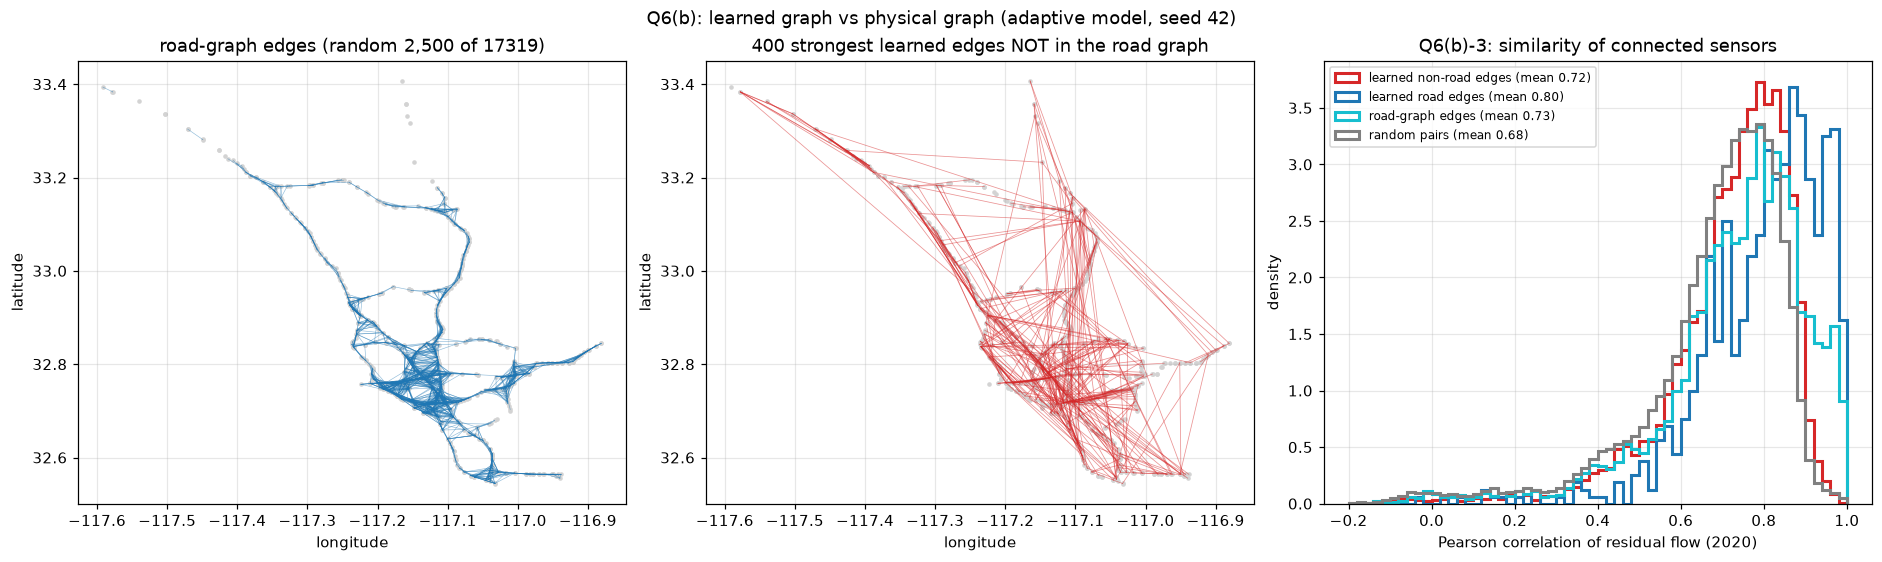

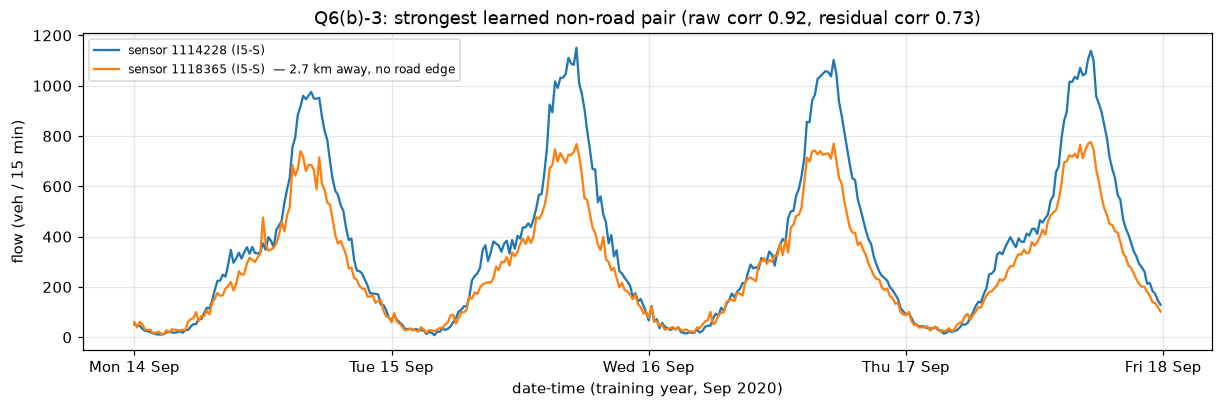

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
lat, lng = meta.Lat.values, meta.Lng.values
ax[0].scatter(lng, lat, s=4, c='lightgray')
ri_, rj_ = np.where(road & ~road.T | road)
sub = rng.choice(len(ri_), min(2500, len(ri_)), replace=False)
for i, j in zip(ri_[sub], rj_[sub]): ax[0].plot([lng[i], lng[j]], [lat[i], lat[j]], color='tab:blue', lw=.4, alpha=.5)
ax[0].set_title('road-graph edges (random 2,500 of %d)' % len(ri_)); ax[0].set_xlabel('longitude'); ax[0].set_ylabel('latitude')
ax[1].scatter(lng, lat, s=4, c='lightgray')
li_, lj_ = np.where(nonroad); order2 = np.argsort(-off[li_, lj_])[:400]
for t_ in order2: i, j = li_[t_], lj_[t_]; ax[1].plot([lng[i], lng[j]], [lat[i], lat[j]], color='tab:red', lw=.5, alpha=.5)
ax[1].set_title('400 strongest learned edges NOT in the road graph'); ax[1].set_xlabel('longitude'); ax[1].set_ylabel('latitude')
for lab, M_, c in (('learned non-road edges', nonroad, 'tab:red'), ('learned road edges', L_edges & road, 'tab:blue'), ('road-graph edges', road, 'tab:cyan'), ('random pairs', rand_M, 'gray')):
    v = C_res[M_]; v = v[~np.isnan(v)]; ax[2].hist(v, bins=60, range=(-0.2, 1), density=True, histtype='step', lw=2, color=c, label=f'{lab} (mean {v.mean():.2f})')
ax[2].set_xlabel('Pearson correlation of residual flow (2020)'); ax[2].set_ylabel('density'); ax[2].set_title('Q6(b)-3: similarity of connected sensors'); ax[2].legend(fontsize=8)
fig.suptitle('Q6(b): learned graph vs physical graph (adaptive model, seed 42)'); fig.savefig(f'{FIG}/q6b_graph_visualisation.png', dpi=160); plt.show()

# one concrete example: series of the strongest non-road pair
i, j = top_idx[0]; w0, w1 = pd.Timestamp('2020-09-14'), pd.Timestamp('2020-09-18'); m_ = (times >= w0) & (times < w1)
fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
ax.plot(times[m_], Xraw[m_, i], label=f'sensor {ids[i]} ({meta.Fwy[i]})'); ax.plot(times[m_], Xraw[m_, j], label=f'sensor {ids[j]} ({meta.Fwy[j]})  — {DIST[i, j]:.1f} km away, no road edge')
ax.set_xlabel('date-time (training year, Sep 2020)'); ax.set_ylabel('flow (veh / 15 min)'); ax.set_title(f'Q6(b)-3: strongest learned non-road pair (raw corr {C_raw[i, j]:.2f}, residual corr {C_res[i, j]:.2f})'); ax.legend(fontsize=8)
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b')); fig.savefig(f'{FIG}/q6b_nonroad_pair_series.png', dpi=160); plt.show()

In [11]:
base_fwy = np.array(meta.Fwy.str.replace(r'-[NSEW]$', '', regex=True).astype(str).tolist())
same = base_fwy[:, None] == base_fwy[None, :]
alive_ = ~(dead[:, None] | dead[None, :]) & ~eye
R6['same_freeway'] = dict(learned_nonroad=float(same[nonroad & alive_].mean()), learned_road=float(same[L_edges & road & alive_].mean()), road_edges=float(same[road].mean()), random_pairs=float(same[alive_].mean()))
print('share of edges joining sensors on the same freeway:', {k: round(v, 3) for k, v in R6['same_freeway'].items()})

share of edges joining sensors on the same freeway: {'learned_nonroad': 0.182, 'learned_road': 0.625, 'road_edges': 0.498, 'random_pairs': 0.14}


### Evidence for Q6(c)(3): do the dependencies between neighbouring sensors change with the time regime?
Mean Pearson correlation (training year only, residual flow = flow minus the sensor's own weekly profile) between the endpoints of road edges, of learned non-road edges and of random pairs, computed separately inside three regimes: weekday rush hours (07–09 h and 16–18 h), night (00–05 h), weekend midday (10–15 h). A static graph uses one weight per pair for all of them.

In [12]:
tt_h, tt_d = tt.hour.values, tt.dayofweek.values
regimes = {'weekday rush (7-9h, 16-18h)': (tt_d < 5) & np.isin(tt_h, [7, 8, 16, 17]), 'night (0-5h)': tt_h < 5, 'weekend midday (10-15h)': (tt_d >= 5) & (tt_h >= 10) & (tt_h < 16)}
rc = {}
for rn, m_ in regimes.items():
    Cg = pd.DataFrame(Xres[m_]).corr(min_periods=300).values
    rc[rn] = {g: float(np.nanmean(Cg[M_ & alive_pair])) for g, M_ in (('road edges', road), ('learned non-road edges', nonroad), ('random pairs', rand_M))}
R6['regime_corr'] = rc; print(pd.DataFrame(rc).round(3).to_string())

                        weekday rush (7-9h, 16-18h)  night (0-5h)  weekend midday (10-15h)
road edges                                    0.724         0.540                    0.829
learned non-road edges                        0.710         0.517                    0.799
random pairs                                  0.672         0.474                    0.767


### Q6(b) — answers to the four questions

In [13]:
q = R6['learned_graph']['adaptive model']; qs = R6['learned_graph']['adaptive model + self path']; ex_ = R6['learned_graph_extra']; cs = R6['corr_stats']
dk = q['dist_km']
top_alive = [r for r in R6['top_nonroad_examples'][:3]]
ex_txt = '; '.join(f"sensors {r['sensor_i']} ({r['fwy_i']}) and {r['sensor_j']} ({r['fwy_j']}), {r['km']} km apart, weight {r['weight']}, residual correlation {r['corr_resid']}" for r in top_alive)
txt = f"""**(1) Are the strongest learned connections in the road graph? — partly.** For the adaptive model (the one that follows the assignment formula) {100*q['frac_learned_edges_in_road']:.1f} % of its {q['n_learned_edges_nonself']:,} non-self learned edges are road edges (directed i→j; {100*q['frac_learned_edges_in_road_either']:.1f} % if either direction counts), against {100*q['road_edge_density']:.1f} % ({100*q['road_edge_density_either']:.1f} %) expected for random pairs, and only {100*q['frac_road_edges_recovered']:.1f} % of the {int(road.sum()):,} road edges are re-discovered. Overlap is much higher for the *strongest* edges: overlap@1 (each sensor's single strongest learned neighbour is a road neighbour) = {100*q['overlap_at_1_directed']:.0f} % ({100*q['overlap_at_1_either_dir']:.0f} % either direction), overlap@5 = {100*q['overlap_at_5_directed']:.0f} %, @10 = {100*q['overlap_at_10_directed']:.0f} %, @19 = {100*q['overlap_at_19_directed']:.0f} %, and {100*q['global_top500_in_road']:.0f} % of the 500 globally strongest edges are road edges (≈ {q['global_top500_in_road']/q['road_edge_density']:.0f}× chance). So the road graph is recovered for the top few neighbours, but the 20-edge neighbourhoods are mostly *not* road neighbours. The adaptive part of the hybrid model behaves alike (overlap@1 {100*R6['learned_graph']['hybrid model (adaptive part)']['overlap_at_1_directed']:.0f} %), and the models with a self path are close to chance level (overlap@1 {100*qs['overlap_at_1_directed']:.0f} %, all learned edges {100*qs['frac_learned_edges_in_road']:.1f} % vs {100*qs['road_edge_density']:.1f} % chance): when the layer has its own self path, the learned graph no longer needs to reproduce the road neighbours and behaves like a general mixing matrix.

**(2) Do learned connections link geographically near sensors? — only weakly.** Median geographic distance of connected pairs: road edges {dk['road_edges']['median']:.1f} km (90 % within {dk['road_edges']['p90']:.1f} km), learned edges {dk['learned_all']['median']:.1f} km, random pairs {dk['random_pairs']['median']:.1f} km. All learned edges are only slightly closer than random ({100*dk['learned_all']['frac_lt_5km']:.0f} % vs {100*dk['random_pairs']['frac_lt_5km']:.0f} % of pairs within 5 km), but the 2,000 strongest ones are noticeably more local (median {dk['learned_top2000']['median']:.1f} km, {100*dk['learned_top2000']['frac_lt_5km']:.0f} % within 5 km). The learned graph is clearly not a distance graph (middle panel of `q6b_learned_vs_road_stats.png`: CDFs).

**(3) Can the learned graph capture dependencies absent from the physical graph? — it does link such sensors, and they are similar.** {100*R6['frac_edges_nonroad']:.1f} % of the learned edges are absent from the road graph in both directions, and {100*R6['frac_nonroad_edges_far_gt5km']:.0f} % of those link sensors more than 5 km apart. The traffic at their endpoints is more similar than for random pairs: mean Pearson correlation of the 2020 series is {cs['raw']['learned_nonroad']['mean']:.3f} for learned non-road edges vs {cs['raw']['random_pairs']['mean']:.3f} for random pairs and {cs['raw']['road_edges']['mean']:.3f} for road edges (raw flow); after removing each sensor's weekly profile (isolating co-movement beyond the shared daily cycle) {cs['residual']['learned_nonroad']['mean']:.3f} vs {cs['residual']['random_pairs']['mean']:.3f} (random) and {cs['residual']['road_edges']['mean']:.3f} (road edges); learned edges that coincide with road edges are the most similar ({cs['residual']['learned_road']['mean']:.3f}). The gain over random pairs is real but modest, because all sensors in one county share a strong common signal. Examples of strong learned non-road edges between sensors with data: {ex_txt} (full list in `results/q6b_top_nonroad_edges.csv`, series example in `figures/q6b_nonroad_pair_series.png`). Only {100*R6['same_freeway']['learned_nonroad']:.0f} % of the learned non-road edges join two sensors on the same freeway (random pairs {100*R6['same_freeway']['random_pairs']:.0f} %, road edges {100*R6['same_freeway']['road_edges']:.0f} %), so most of them connect *different* freeways; a plausible reading (not tested here) is that they encode demand similarity — sensors that serve related commuting flows — rather than corridor adjacency. The learned graph is also very uneven: a few hub sensors are selected by up to {ex_['hub_in_degree_max']} of the 716 rows (mean {ex_['hub_in_degree_mean']:.0f}). *Check on a possible shortcut:* {100*ex_['frac_learned_edges_touching_dead']:.1f} % of all learned edges (and {100*ex_['frac_top500_touching_dead']:.0f} % of the 500 strongest) touch one of the {ex_['n_dead']} sensors that have no observation in the training year, which is about the {100*ex_['expected_if_random']:.1f} % expected by chance, and none of the five largest hubs is such a sensor, so the constant inputs of dead sensors are *not* what the model exploits. Edges to these sensors are nevertheless excluded from the examples (their correlation is undefined).

**(4) Why can a learned adjacency be better or worse than a fixed one?** *Better:* it is data-driven — it can pick the sensors whose features help the forecast (similar demand patterns, other carriageways, other corridors) whether or not they are close on the road, and it can be sharper than the distance kernel (row weights concentrated on {ex_['eff_neighbours_adaptive']:.1f} effective neighbours versus {ex_['eff_neighbours_fixed']:.1f}); the road graph averages many neighbours with weights that depend only on distance. Measured: adaptive {mae('stgnn_adaptive'):.1f} vs fixed {mae('stgnn_fixed'):.1f} (spec formula) and {mae('stgnn_adaptive_skip'):.1f} vs {mae('stgnn_fixed_skip'):.1f} (with self path). *Worse or riskier:* it has no inductive bias — N² graph entries parameterised by {RES42['stgnn_adaptive']['params']-RES42['stgnn_fixed']['params']:,} extra embedding parameters that can fit the particular training regime: in the spec-formula runs the adaptive model has the same training error as temporal-only but a much larger train→test gap ({mae('stgnn_adaptive')-tl('stgnn_adaptive'):.1f} vs {mae('temporal_only')-tl('temporal_only'):.1f}); the factorisation E1E2ᵀ is not identifiable (rotating the embeddings gives the same graph) and the top-k selection is non-smooth, so the learned edges should not be over-interpreted (seed-to-seed std of test MAE: fixed {SD['stgnn_fixed']['test_MAE_std']:.1f}, adaptive {SD['stgnn_adaptive']['test_MAE_std']:.1f}, hybrid {SD['stgnn_hybrid']['test_MAE_std']:.1f}); it may exploit correlations that are common-mode rather than causal; it costs more per epoch and (here) needed more epochs ({RES42['stgnn_adaptive']['epochs_run']} vs {RES42['stgnn_fixed']['epochs_run']}); and it cannot be applied to a new sensor without retraining, whereas the road graph generalises through geometry. The fixed graph is the opposite: no extra parameters and a physically meaningful prior, but a fixed distance cut-off and weights that may be wrong for traffic (the kernel says nothing about the direction of flow, ramps, or demand similarity)."""
narrate('6b', txt)

**(1) Are the strongest learned connections in the road graph? — partly.** For the adaptive model (the one that follows the assignment formula) 5.9 % of its 14,252 non-self learned edges are road edges (directed i→j; 7.3 % if either direction counts), against 3.4 % (4.1 %) expected for random pairs, and only 4.8 % of the 17,319 road edges are re-discovered. Overlap is much higher for the *strongest* edges: overlap@1 (each sensor's single strongest learned neighbour is a road neighbour) = 25 % (34 % either direction), overlap@5 = 12 %, @10 = 8 %, @19 = 6 %, and 30 % of the 500 globally strongest edges are road edges (≈ 9× chance). So the road graph is recovered for the top few neighbours, but the 20-edge neighbourhoods are mostly *not* road neighbours. The adaptive part of the hybrid model behaves alike (overlap@1 20 %), and the models with a self path are close to chance level (overlap@1 6 %, all learned edges 4.2 % vs 3.4 % chance): when the layer has its own self path, the learned graph no longer needs to reproduce the road neighbours and behaves like a general mixing matrix.

**(2) Do learned connections link geographically near sensors? — only weakly.** Median geographic distance of connected pairs: road edges 1.4 km (90 % within 3.2 km), learned edges 15.5 km, random pairs 19.0 km. All learned edges are only slightly closer than random (21 % vs 16 % of pairs within 5 km), but the 2,000 strongest ones are noticeably more local (median 7.2 km, 39 % within 5 km). The learned graph is clearly not a distance graph (middle panel of `q6b_learned_vs_road_stats.png`: CDFs).

**(3) Can the learned graph capture dependencies absent from the physical graph? — it does link such sensors, and they are similar.** 92.7 % of the learned edges are absent from the road graph in both directions, and 86 % of those link sensors more than 5 km apart. The traffic at their endpoints is more similar than for random pairs: mean Pearson correlation of the 2020 series is 0.872 for learned non-road edges vs 0.843 for random pairs and 0.855 for road edges (raw flow); after removing each sensor's weekly profile (isolating co-movement beyond the shared daily cycle) 0.717 vs 0.677 (random) and 0.734 (road edges); learned edges that coincide with road edges are the most similar (0.800). The gain over random pairs is real but modest, because all sensors in one county share a strong common signal. Examples of strong learned non-road edges between sensors with data: sensors 1114228 (I5-S) and 1118365 (I5-S), 2.7 km apart, weight 0.763, residual correlation 0.728; sensors 1111514 (I8-E) and 1126257 (SR52-W), 8.6 km apart, weight 0.625, residual correlation 0.745; sensors 1119984 (I5-N) and 1121715 (I5-N), 10.1 km apart, weight 0.615, residual correlation 0.884 (full list in `results/q6b_top_nonroad_edges.csv`, series example in `figures/q6b_nonroad_pair_series.png`). Only 18 % of the learned non-road edges join two sensors on the same freeway (random pairs 14 %, road edges 50 %), so most of them connect *different* freeways; a plausible reading (not tested here) is that they encode demand similarity — sensors that serve related commuting flows — rather than corridor adjacency. The learned graph is also very uneven: a few hub sensors are selected by up to 119 of the 716 rows (mean 20). *Check on a possible shortcut:* 6.0 % of all learned edges (and 4 % of the 500 strongest) touch one of the 19 sensors that have no observation in the training year, which is about the 5.2 % expected by chance, and none of the five largest hubs is such a sensor, so the constant inputs of dead sensors are *not* what the model exploits. Edges to these sensors are nevertheless excluded from the examples (their correlation is undefined).

**(4) Why can a learned adjacency be better or worse than a fixed one?** *Better:* it is data-driven — it can pick the sensors whose features help the forecast (similar demand patterns, other carriageways, other corridors) whether or not they are close on the road, and it can be sharper than the distance kernel (row weights concentrated on 7.6 effective neighbours versus 13.7); the road graph averages many neighbours with weights that depend only on distance. Measured: adaptive 75.5 vs fixed 92.0 (spec formula) and 50.1 vs 56.3 (with self path). *Worse or riskier:* it has no inductive bias — N² graph entries parameterised by 14,320 extra embedding parameters that can fit the particular training regime: in the spec-formula runs the adaptive model has the same training error as temporal-only but a much larger train→test gap (23.3 vs 9.8); the factorisation E1E2ᵀ is not identifiable (rotating the embeddings gives the same graph) and the top-k selection is non-smooth, so the learned edges should not be over-interpreted (seed-to-seed std of test MAE: fixed 0.8, adaptive 0.6, hybrid 0.2); it may exploit correlations that are common-mode rather than causal; it costs more per epoch and (here) needed more epochs (52 vs 45); and it cannot be applied to a new sensor without retraining, whereas the road graph generalises through geometry. The fixed graph is the opposite: no extra parameters and a physically meaningful prior, but a fixed distance cut-off and weights that may be wrong for traffic (the kernel says nothing about the direction of flow, ramps, or demand similarity).

## Q6(c) — Critical discussion

In [14]:
al, al_s = R6['alpha']['stgnn_hybrid'], R6['alpha']['stgnn_hybrid_skip']
gm = R6['group_mae']; best = 'stgnn_adaptive_skip'; gmm = gm['stgnn_adaptive']; fg = R6['flow_by_group']
hr = R6['hour_mae']['temporal_only']; hrb = R6['hour_mae'][best]
data_n = load_json(f'{RES}/q4_q5_summary.json')['Q4a']['window_counts']['train']
hybrid_beats_both = mae('stgnn_hybrid') < min(mae('stgnn_fixed'), mae('stgnn_adaptive')); hs_beats_adp = mae('stgnn_hybrid_skip') < mae('stgnn_adaptive_skip')
mean_hyb_lit = SD['stgnn_hybrid']['test_MAE_mean'] < min(SD['stgnn_fixed']['test_MAE_mean'], SD['stgnn_adaptive']['test_MAE_mean'])
mean_hyb_skip = SD['stgnn_hybrid_skip']['test_MAE_mean'] < min(SD['stgnn_fixed_skip']['test_MAE_mean'], SD['stgnn_adaptive_skip']['test_MAE_mean'])
rg = R6['regime_corr']; rk = list(rg)
txt = f"""**(1) Does a lower error mean the learned graph represents real road connectivity? No.** Two learned graphs are compared (seed 42): **(a) the adaptive graph of the main-table model** (exact assignment formula; test MAE {mae('stgnn_adaptive'):.1f}) and **(b) the adaptive graph of the model with a self path** (the extension; the lowest test error of all seven models, MAE {mae(best):.1f}). In (a) {100*q['frac_learned_edges_in_road']:.1f} % of the learned edges are road edges (chance {100*q['road_edge_density']:.1f} %), overlap@1 is {100*q['overlap_at_1_directed']:.0f} % and the median edge length is {q['dist_km']['learned_all']['median']:.1f} km; in (b), the better forecaster, only {100*qs['frac_learned_edges_in_road']:.1f} % are road edges, overlap@1 is {100*qs['overlap_at_1_directed']:.0f} % and the median edge length is {qs['dist_km']['learned_all']['median']:.1f} km (random pairs {qs['dist_km']['random_pairs']['median']:.1f} km, road edges {qs['dist_km']['road_edges']['median']:.1f} km). So the model with the **lower error has the graph that is closer to random with respect to the road network**: a lower forecasting error does not mean that the learned graph represents the real road connectivity. The adaptive adjacency is a *latent feature-mixing matrix*: it is trained only to reduce the forecast loss, so it connects sensors whose features are useful to each other — because their series are correlated through shared demand, the same corridor or the common daily cycle — which does not imply that vehicles flow from one sensor to the other. It is correlational, not causal, and the direction of A_ij is not the direction of traffic. It could also exploit shortcuts; we checked one candidate (edges into the {ex_['n_dead']} sensors with no data, whose input is a constant) and found them at chance level ({100*ex_['frac_learned_edges_touching_dead']:.1f} % of learned edges vs {100*ex_['expected_if_random']:.1f} % expected), so it is not that one. Conversely, a graph with more road edges is not necessarily better for forecasting: the road graph is the *worse* of the two here in both settings. A learned graph should be read as "which sensors are informative for each other", never as a map of the road network.

**(2) Why might a hybrid outperform fixed or adaptive alone?** The hybrid A = αÂ_fixed + (1−α)A_adaptive combines a physical *prior* (the road graph encodes reliable local structure that is free, needs no data and regularises the model) with a data-driven *correction* (the learned part adds dependencies the road graph misses and can compensate for misleading road links); with a learnable α the model decides how much to trust each. In our runs: spec formula — hybrid {mae('stgnn_hybrid'):.1f} vs fixed {mae('stgnn_fixed'):.1f} and adaptive {mae('stgnn_adaptive'):.1f} (seed 42; {'it beats both' if hybrid_beats_both else 'it does not beat both'}; {nseeds}-seed means {pm('stgnn_hybrid')}, {pm('stgnn_adaptive')}, {pm('stgnn_fixed')}: {'the hybrid is best on average' if mean_hyb_lit else 'the hybrid is not best on average'}), learned α = {al:.2f}, i.e. {100*(1-al):.0f} % of the weight on the learned graph. With the self path: hybrid {mae('stgnn_hybrid_skip'):.1f} vs adaptive {mae('stgnn_adaptive_skip'):.1f} vs fixed {mae('stgnn_fixed_skip'):.1f}; the hybrid {'is slightly better' if hs_beats_adp else 'is not better'} than the adaptive model at seed 42 ({nseeds}-seed means {pm('stgnn_hybrid_skip')} vs {pm('stgnn_adaptive_skip')}: {'hybrid best on average' if mean_hyb_skip else 'hybrid not best on average'}) and α falls to {al_s:.2f}, i.e. the model almost ignores the road prior. So the "prior + correction" argument is supported in the spec-formula setting, where each graph alone is a poor choice, but **not** in the self-path setting, where the learned graph alone is already as good. A plausible (untested here, e.g. by training on less data) explanation is that a prior helps most when data are scarce and matters less with {data_n:,} training windows.

**(3) Limits of a static graph.** One matrix is used for every time of day, day of week and incident, but the dependencies between sensors change. Direct evidence from the training year: the correlation (of residual flow) between the endpoints of road edges is {rg[rk[0]]['road edges']:.2f} on weekday rush hours, {rg[rk[1]]['road edges']:.2f} at night and {rg[rk[2]]['road edges']:.2f} on weekend middays; for learned non-road edges {rg[rk[0]]['learned non-road edges']:.2f} / {rg[rk[1]]['learned non-road edges']:.2f} / {rg[rk[2]]['learned non-road edges']:.2f}; for random pairs {rg[rk[0]]['random pairs']:.2f} / {rg[rk[1]]['random pairs']:.2f} / {rg[rk[2]]['random pairs']:.2f}. A static graph assigns each pair one weight for all of these regimes, so it is a compromise at every time. The forecast error also depends strongly on the regime. For the adaptive graph with self path (the lowest-error model; the main-table adaptive model in brackets) the test MAE is {gm[best]['rush (7-9h, 16-18h)']:.1f} ({gmm['rush (7-9h, 16-18h)']:.1f}) in the rush hours vs {gm[best]['night (0-5h)']:.1f} ({gmm['night (0-5h)']:.1f}) at night (mean flow {fg['rush (7-9h, 16-18h)']:.0f} vs {fg['night (0-5h)']:.0f} veh/15 min, i.e. relative error {100*gm[best]['rush (7-9h, 16-18h)']/fg['rush (7-9h, 16-18h)']:.1f} % ({100*gmm['rush (7-9h, 16-18h)']/fg['rush (7-9h, 16-18h)']:.1f} %) vs {100*gm[best]['night (0-5h)']/fg['night (0-5h)']:.1f} % ({100*gmm['night (0-5h)']/fg['night (0-5h)']:.1f} %)), and {gm[best]['weekday']:.1f} ({gmm['weekday']:.1f}) on weekdays vs {gm[best]['weekend']:.1f} ({gmm['weekend']:.1f}) at weekends; the hour-of-day curve (`q6a_mae_by_hour.png`) peaks at {int(np.argmax(hrb))}:00. These numbers show that error and dependencies vary with the regime; they do not by themselves prove that a dynamic graph would fix it (not tested here). Congestion that builds up at rush hour, incidents and events temporarily change which sensors influence each other, and a static graph cannot represent this. Remedies: time-conditioned or dynamic graphs (the adjacency generated from the current input window or from time-of-day / day-of-week embeddings, as in dynamic-graph and attention-based models), several graphs mixed by a gate (e.g. rush/off-peak, weekday/weekend), or graph structure inferred from the most recent traffic state — at the price of more parameters, more computation and more data."""
narrate('6c', txt)
save_json(NARR, f'{RES}/q6_narrative.json')

**(1) Does a lower error mean the learned graph represents real road connectivity? No.** Two learned graphs are compared (seed 42): **(a) the adaptive graph of the main-table model** (exact assignment formula; test MAE 75.5) and **(b) the adaptive graph of the model with a self path** (the extension; the lowest test error of all seven models, MAE 50.1). In (a) 5.9 % of the learned edges are road edges (chance 3.4 %), overlap@1 is 25 % and the median edge length is 15.5 km; in (b), the better forecaster, only 4.2 % are road edges, overlap@1 is 6 % and the median edge length is 16.6 km (random pairs 19.0 km, road edges 1.4 km). So the model with the **lower error has the graph that is closer to random with respect to the road network**: a lower forecasting error does not mean that the learned graph represents the real road connectivity. The adaptive adjacency is a *latent feature-mixing matrix*: it is trained only to reduce the forecast loss, so it connects sensors whose features are useful to each other — because their series are correlated through shared demand, the same corridor or the common daily cycle — which does not imply that vehicles flow from one sensor to the other. It is correlational, not causal, and the direction of A_ij is not the direction of traffic. It could also exploit shortcuts; we checked one candidate (edges into the 19 sensors with no data, whose input is a constant) and found them at chance level (6.0 % of learned edges vs 5.2 % expected), so it is not that one. Conversely, a graph with more road edges is not necessarily better for forecasting: the road graph is the *worse* of the two here in both settings. A learned graph should be read as "which sensors are informative for each other", never as a map of the road network.

**(2) Why might a hybrid outperform fixed or adaptive alone?** The hybrid A = αÂ_fixed + (1−α)A_adaptive combines a physical *prior* (the road graph encodes reliable local structure that is free, needs no data and regularises the model) with a data-driven *correction* (the learned part adds dependencies the road graph misses and can compensate for misleading road links); with a learnable α the model decides how much to trust each. In our runs: spec formula — hybrid 72.2 vs fixed 92.0 and adaptive 75.5 (seed 42; it beats both; 3-seed means 72.1 ± 0.2, 74.8 ± 0.6, 91.1 ± 0.8: the hybrid is best on average), learned α = 0.28, i.e. 72 % of the weight on the learned graph. With the self path: hybrid 50.4 vs adaptive 50.1 vs fixed 56.3; the hybrid is not better than the adaptive model at seed 42 (3-seed means 50.6 ± 0.2 vs 50.2 ± 0.1: hybrid not best on average) and α falls to 0.05, i.e. the model almost ignores the road prior. So the "prior + correction" argument is supported in the spec-formula setting, where each graph alone is a poor choice, but **not** in the self-path setting, where the learned graph alone is already as good. A plausible (untested here, e.g. by training on less data) explanation is that a prior helps most when data are scarce and matters less with 35,125 training windows.

**(3) Limits of a static graph.** One matrix is used for every time of day, day of week and incident, but the dependencies between sensors change. Direct evidence from the training year: the correlation (of residual flow) between the endpoints of road edges is 0.72 on weekday rush hours, 0.54 at night and 0.83 on weekend middays; for learned non-road edges 0.71 / 0.52 / 0.80; for random pairs 0.67 / 0.47 / 0.77. A static graph assigns each pair one weight for all of these regimes, so it is a compromise at every time. The forecast error also depends strongly on the regime. For the adaptive graph with self path (the lowest-error model; the main-table adaptive model in brackets) the test MAE is 69.2 (104.3) in the rush hours vs 22.7 (35.4) at night (mean flow 1041 vs 160 veh/15 min, i.e. relative error 6.6 % (10.0 %) vs 14.1 % (22.1 %)), and 52.6 (77.3) on weekdays vs 43.8 (71.0) at weekends; the hour-of-day curve (`q6a_mae_by_hour.png`) peaks at 7:00. These numbers show that error and dependencies vary with the regime; they do not by themselves prove that a dynamic graph would fix it (not tested here). Congestion that builds up at rush hour, incidents and events temporarily change which sensors influence each other, and a static graph cannot represent this. Remedies: time-conditioned or dynamic graphs (the adjacency generated from the current input window or from time-of-day / day-of-week embeddings, as in dynamic-graph and attention-based models), several graphs mixed by a gate (e.g. rush/off-peak, weekday/weekend), or graph structure inferred from the most recent traffic state — at the price of more parameters, more computation and more data.

In [15]:
save_json(R6, f'{RES}/q6_results.json'); print('saved results/q6_results.json')

saved results/q6_results.json
